#### Omar Aljasem
****16.11.2026****

### Exercise
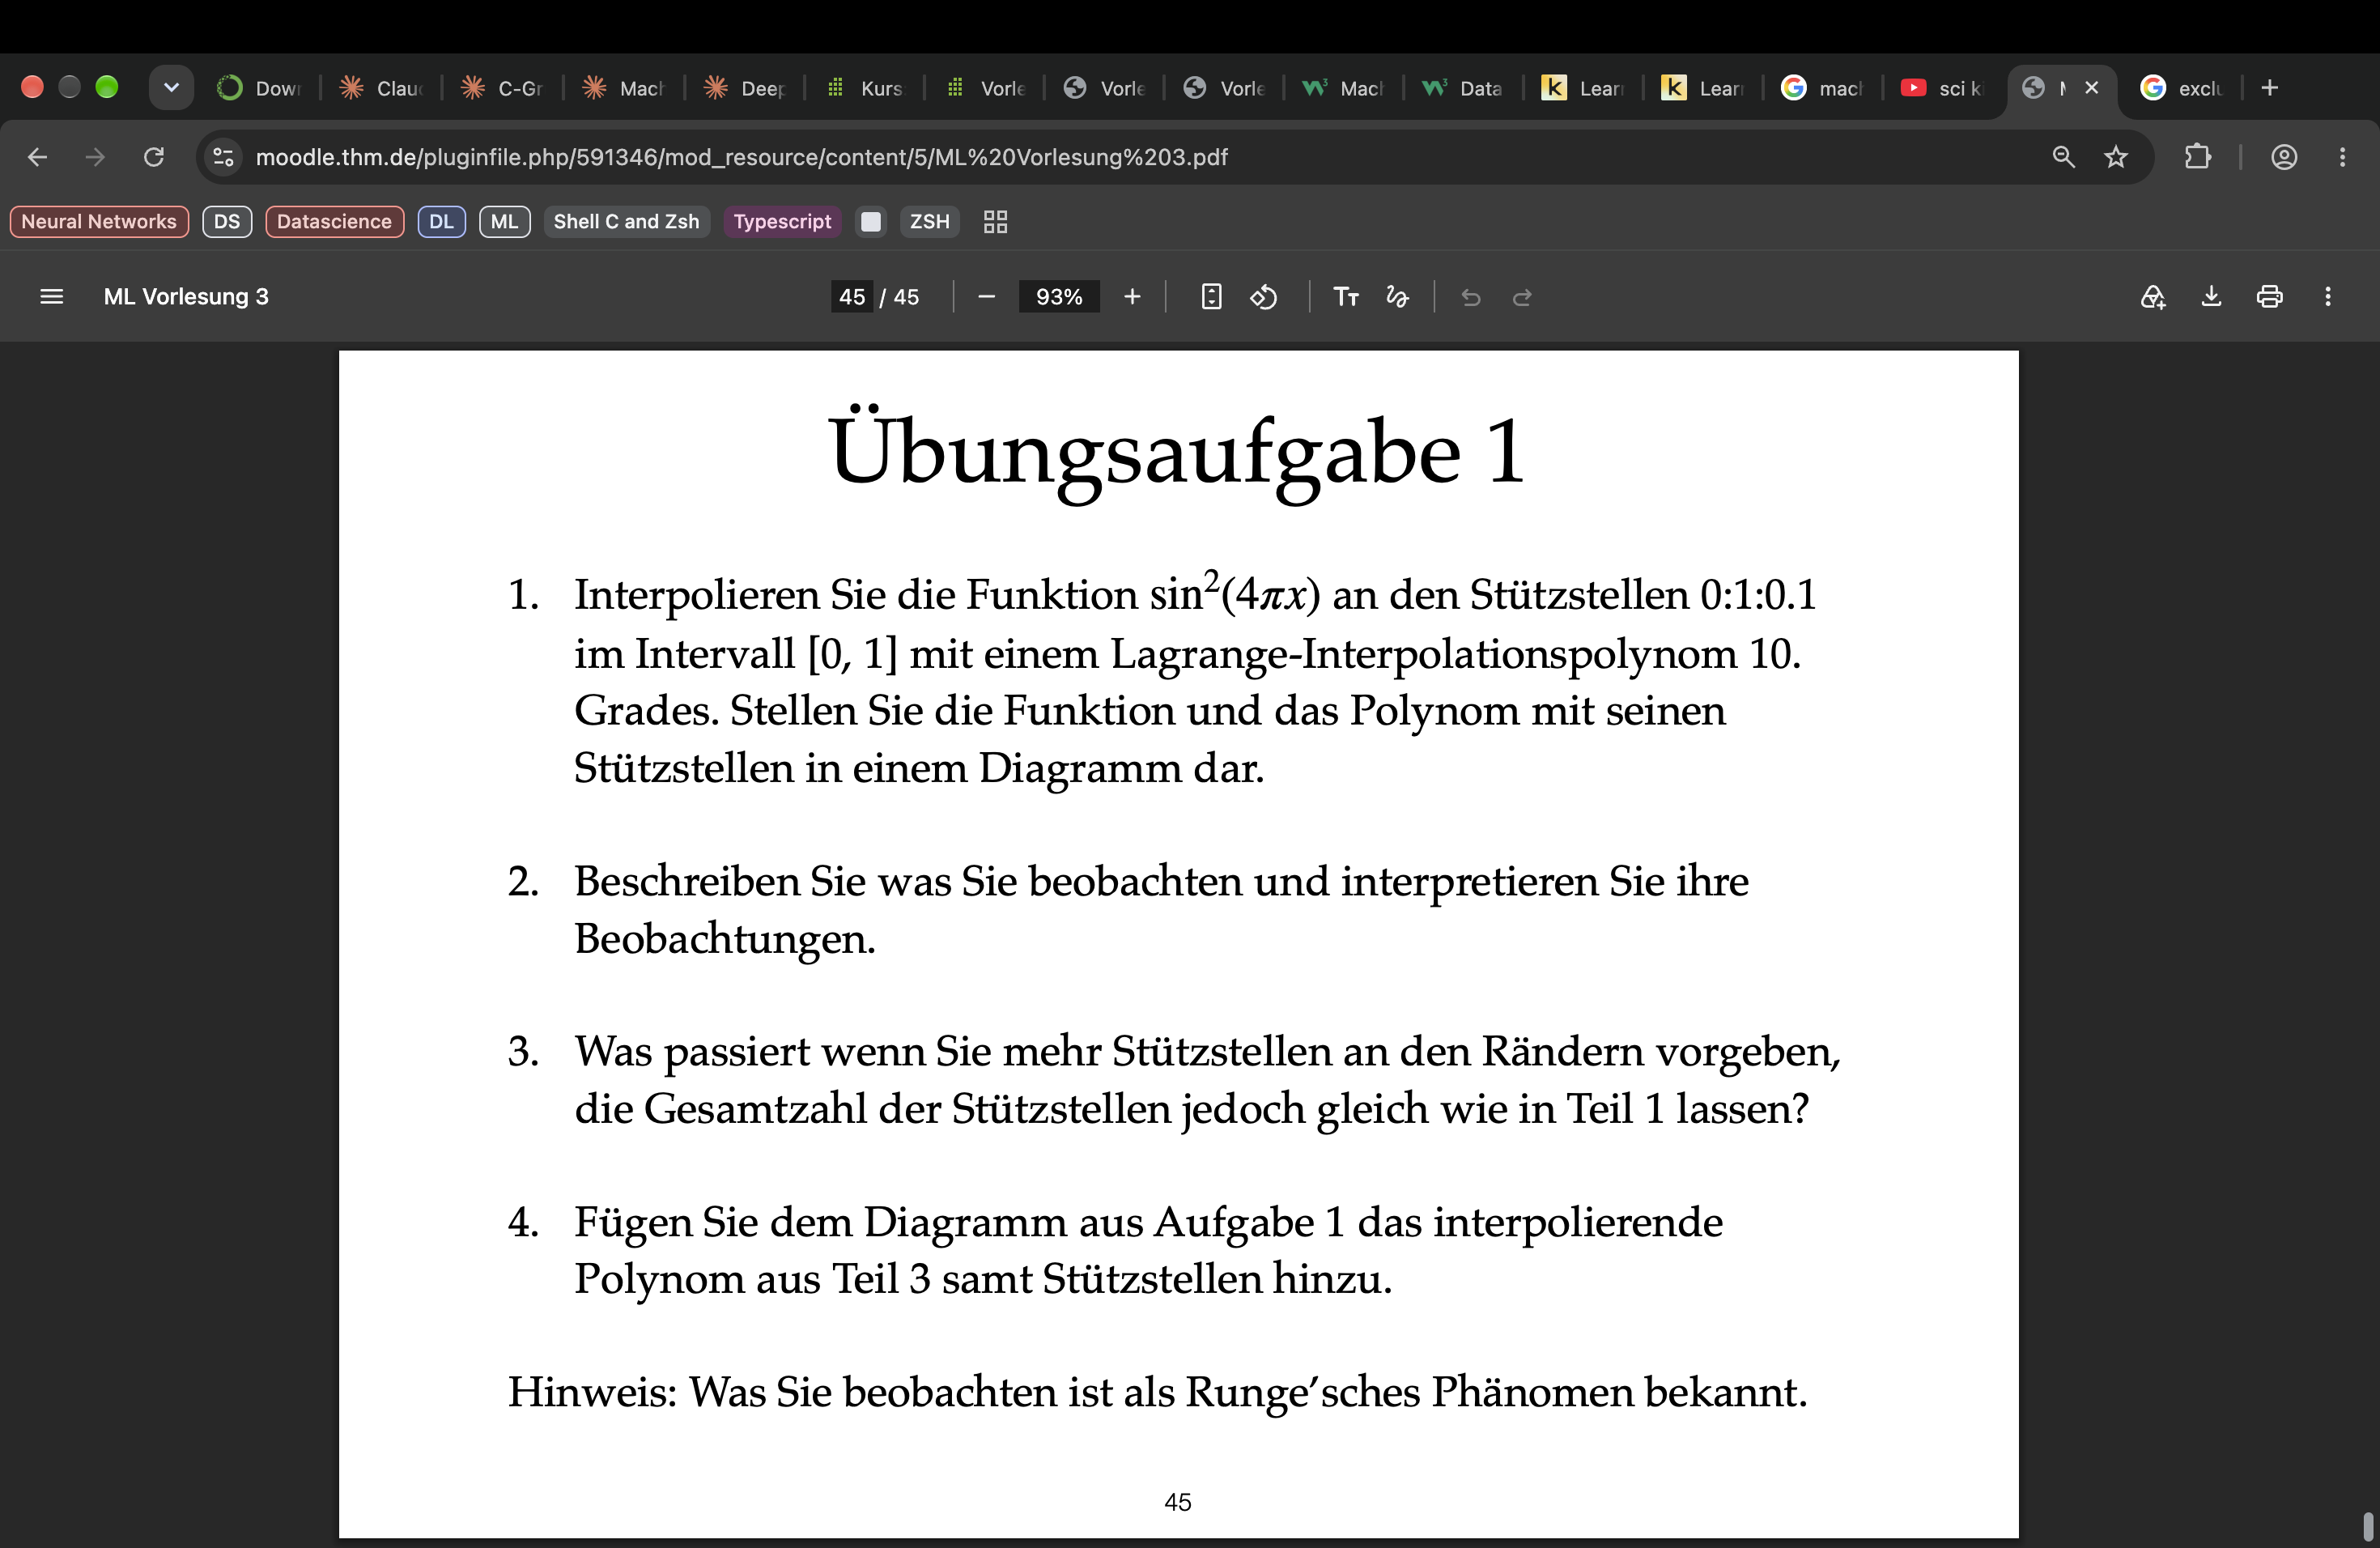
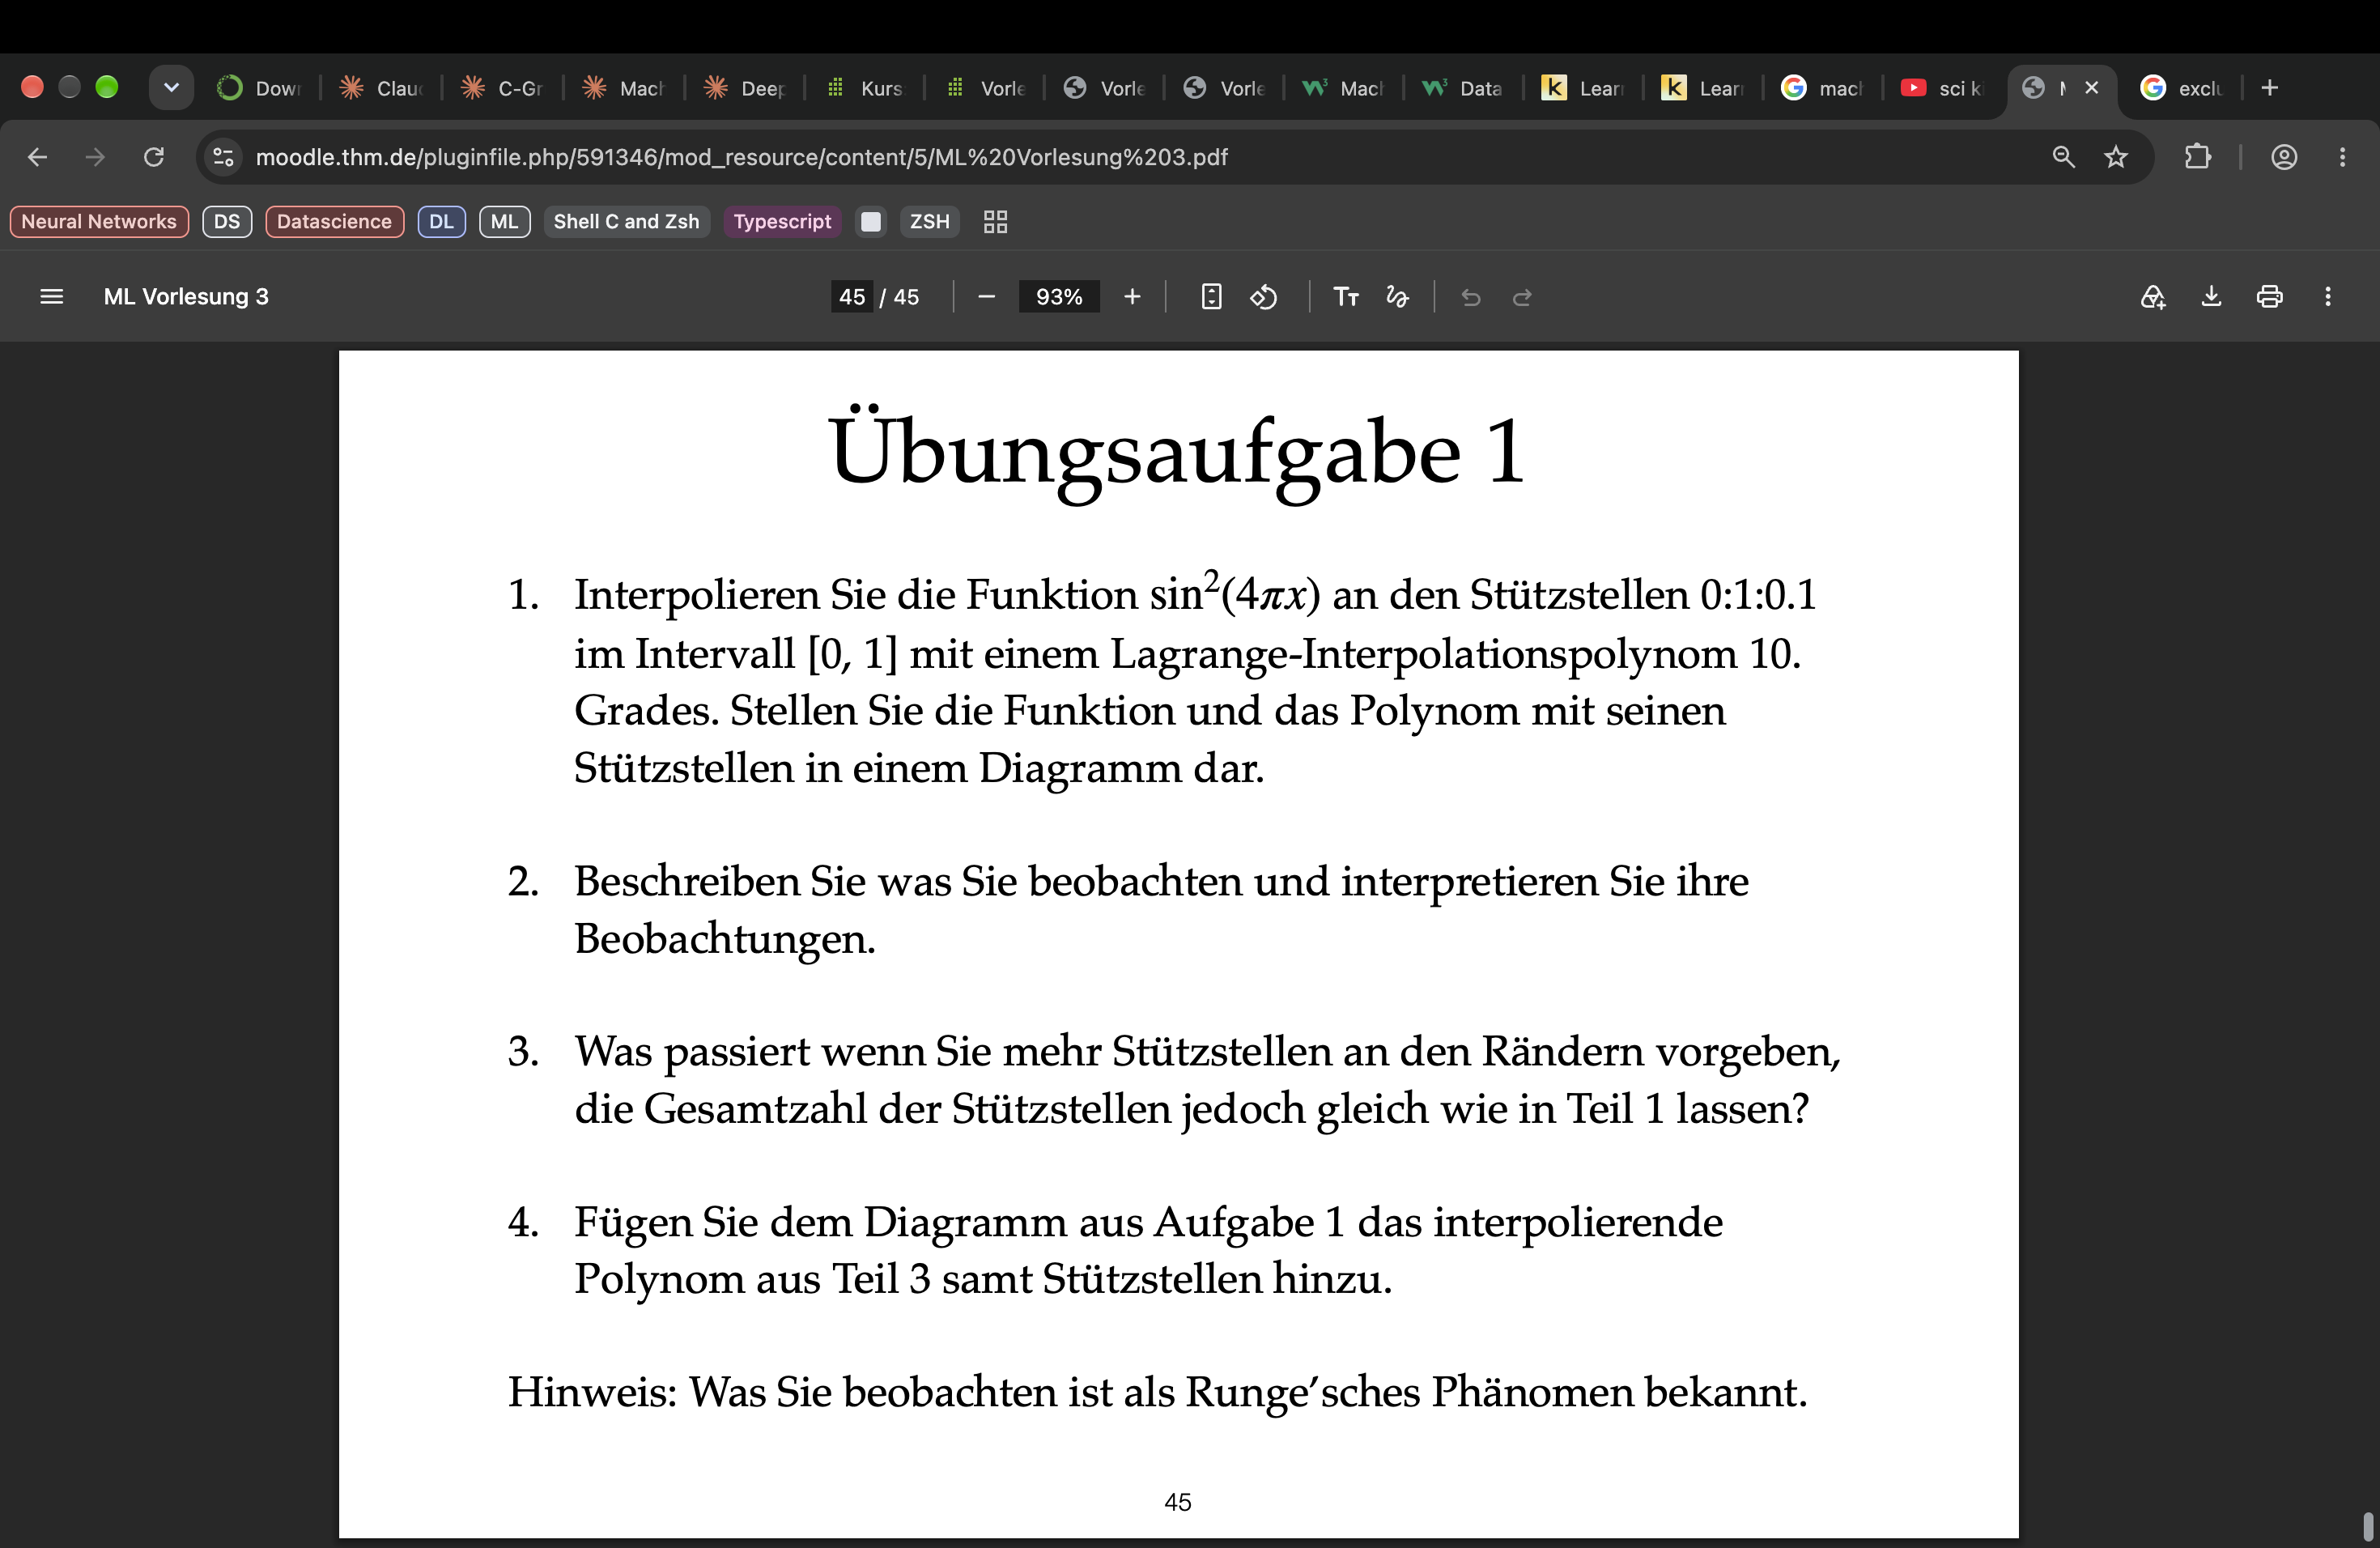
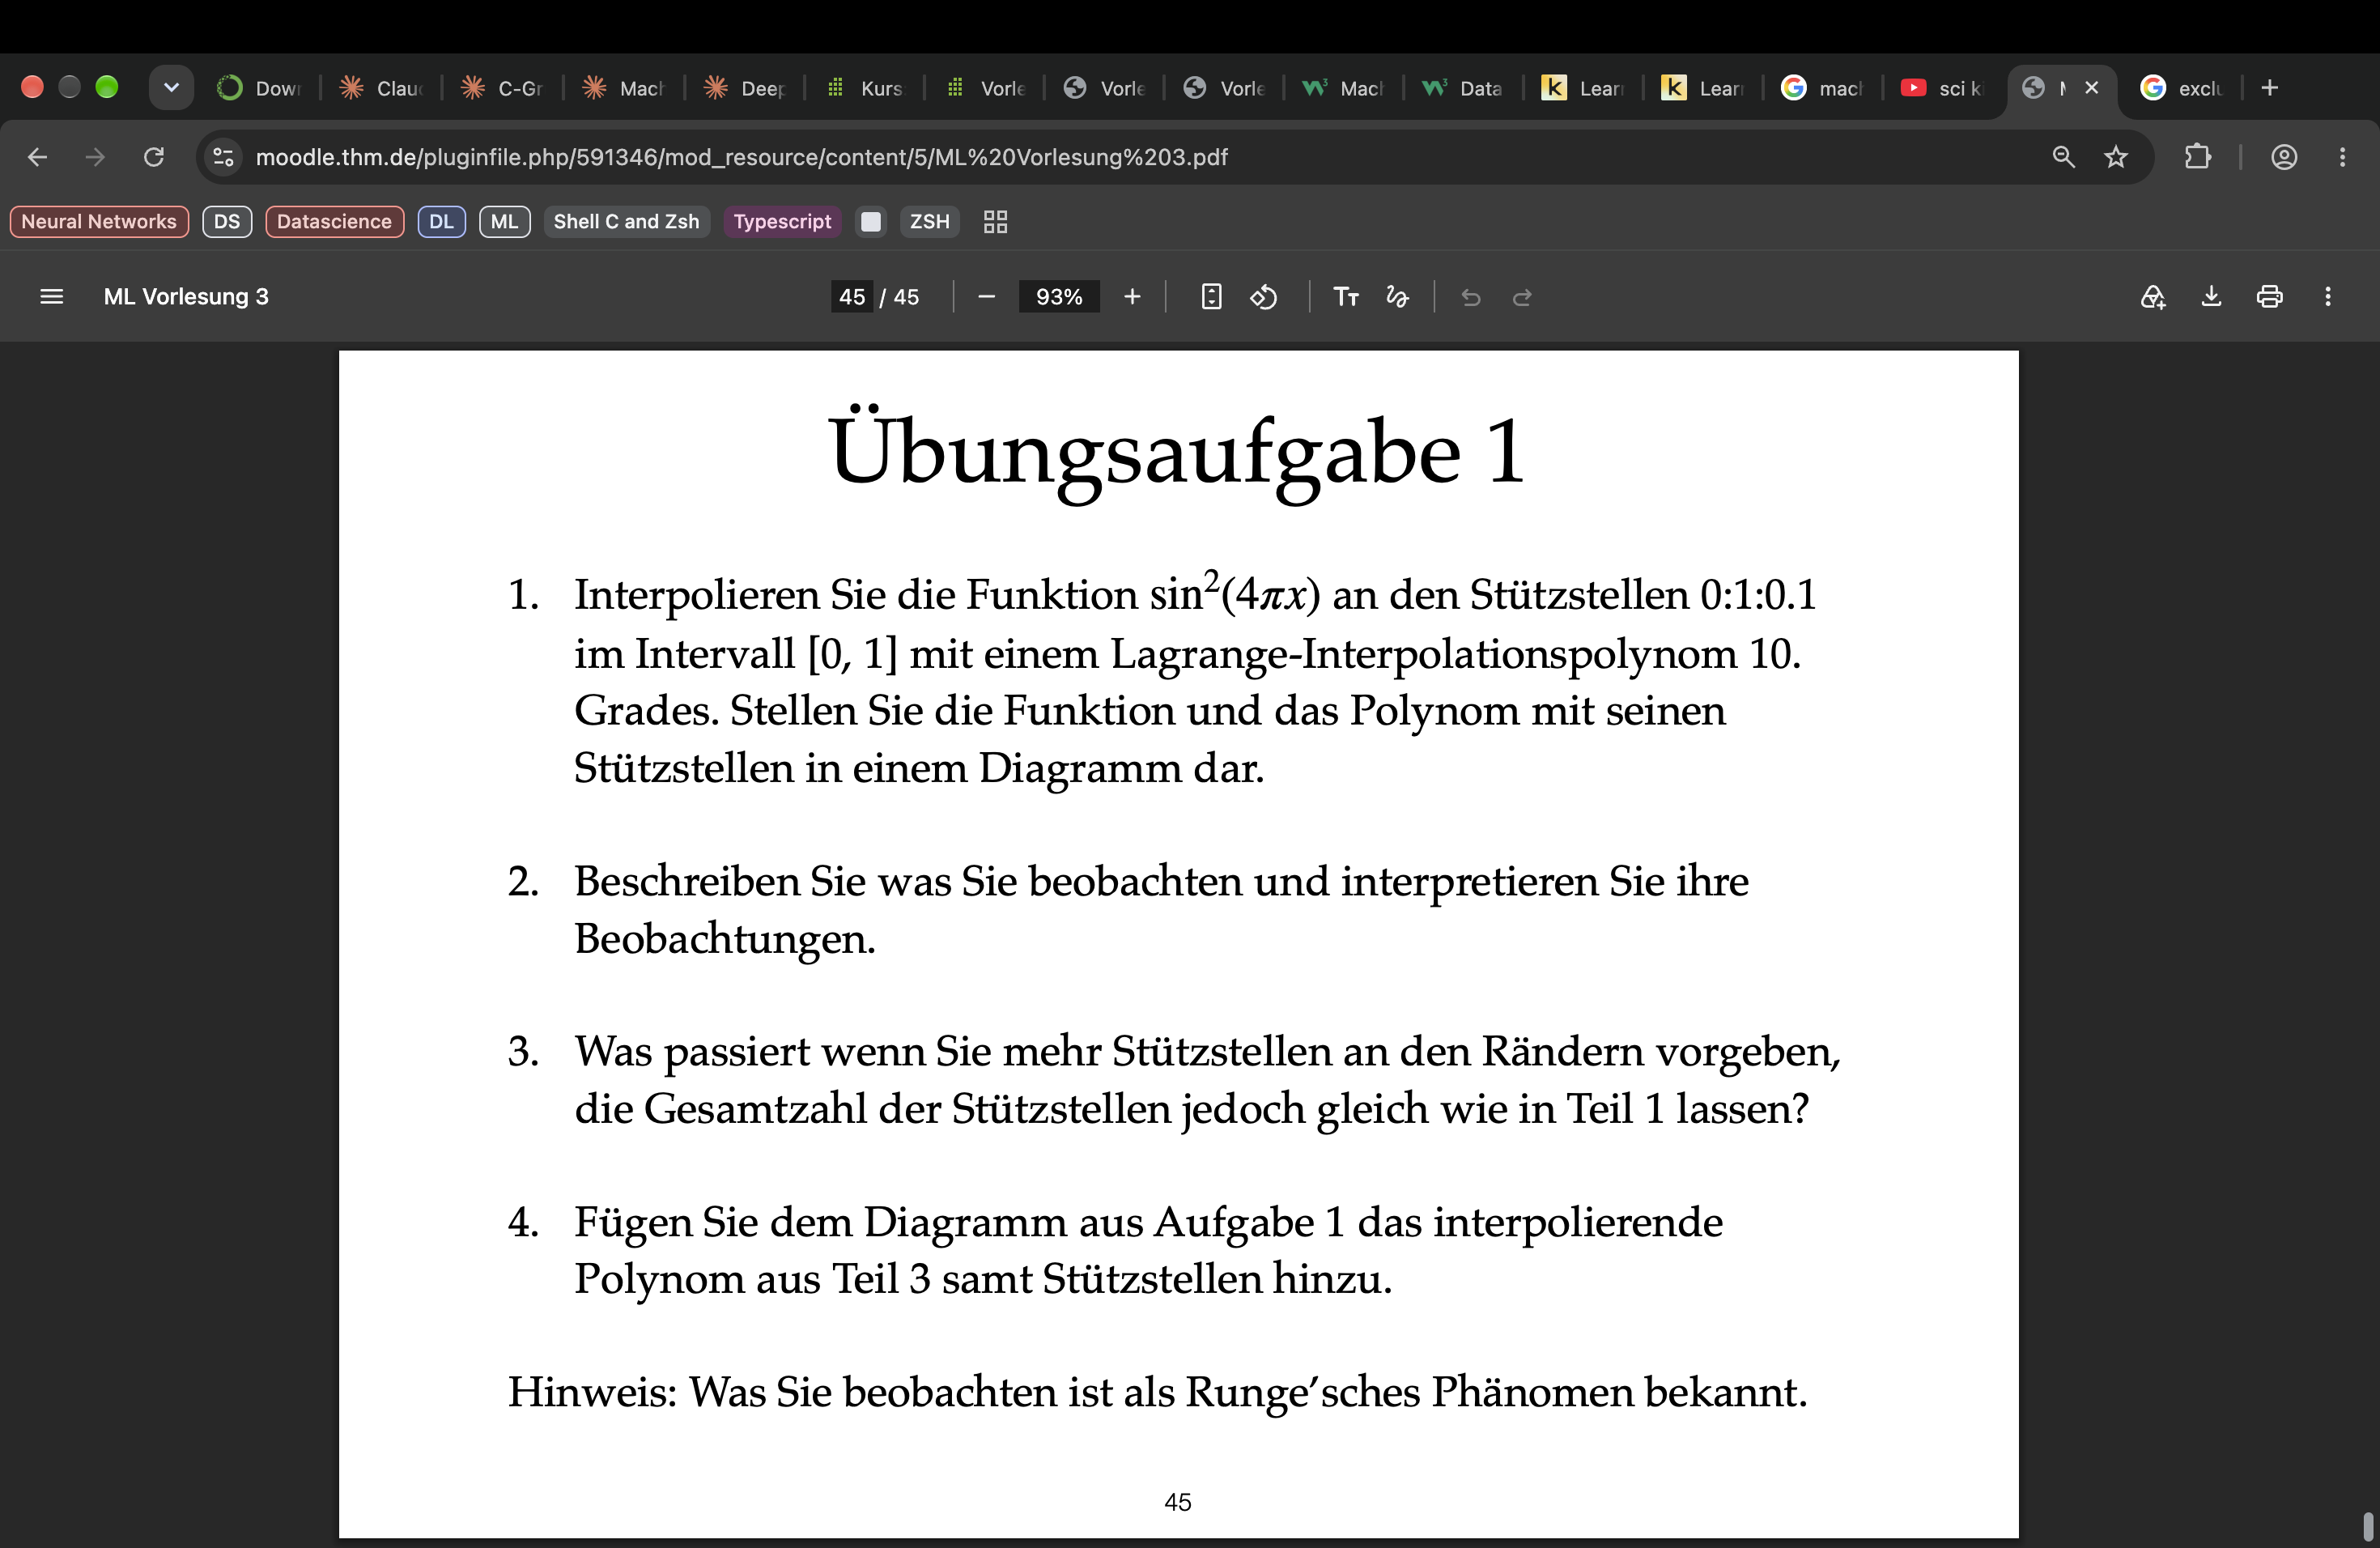
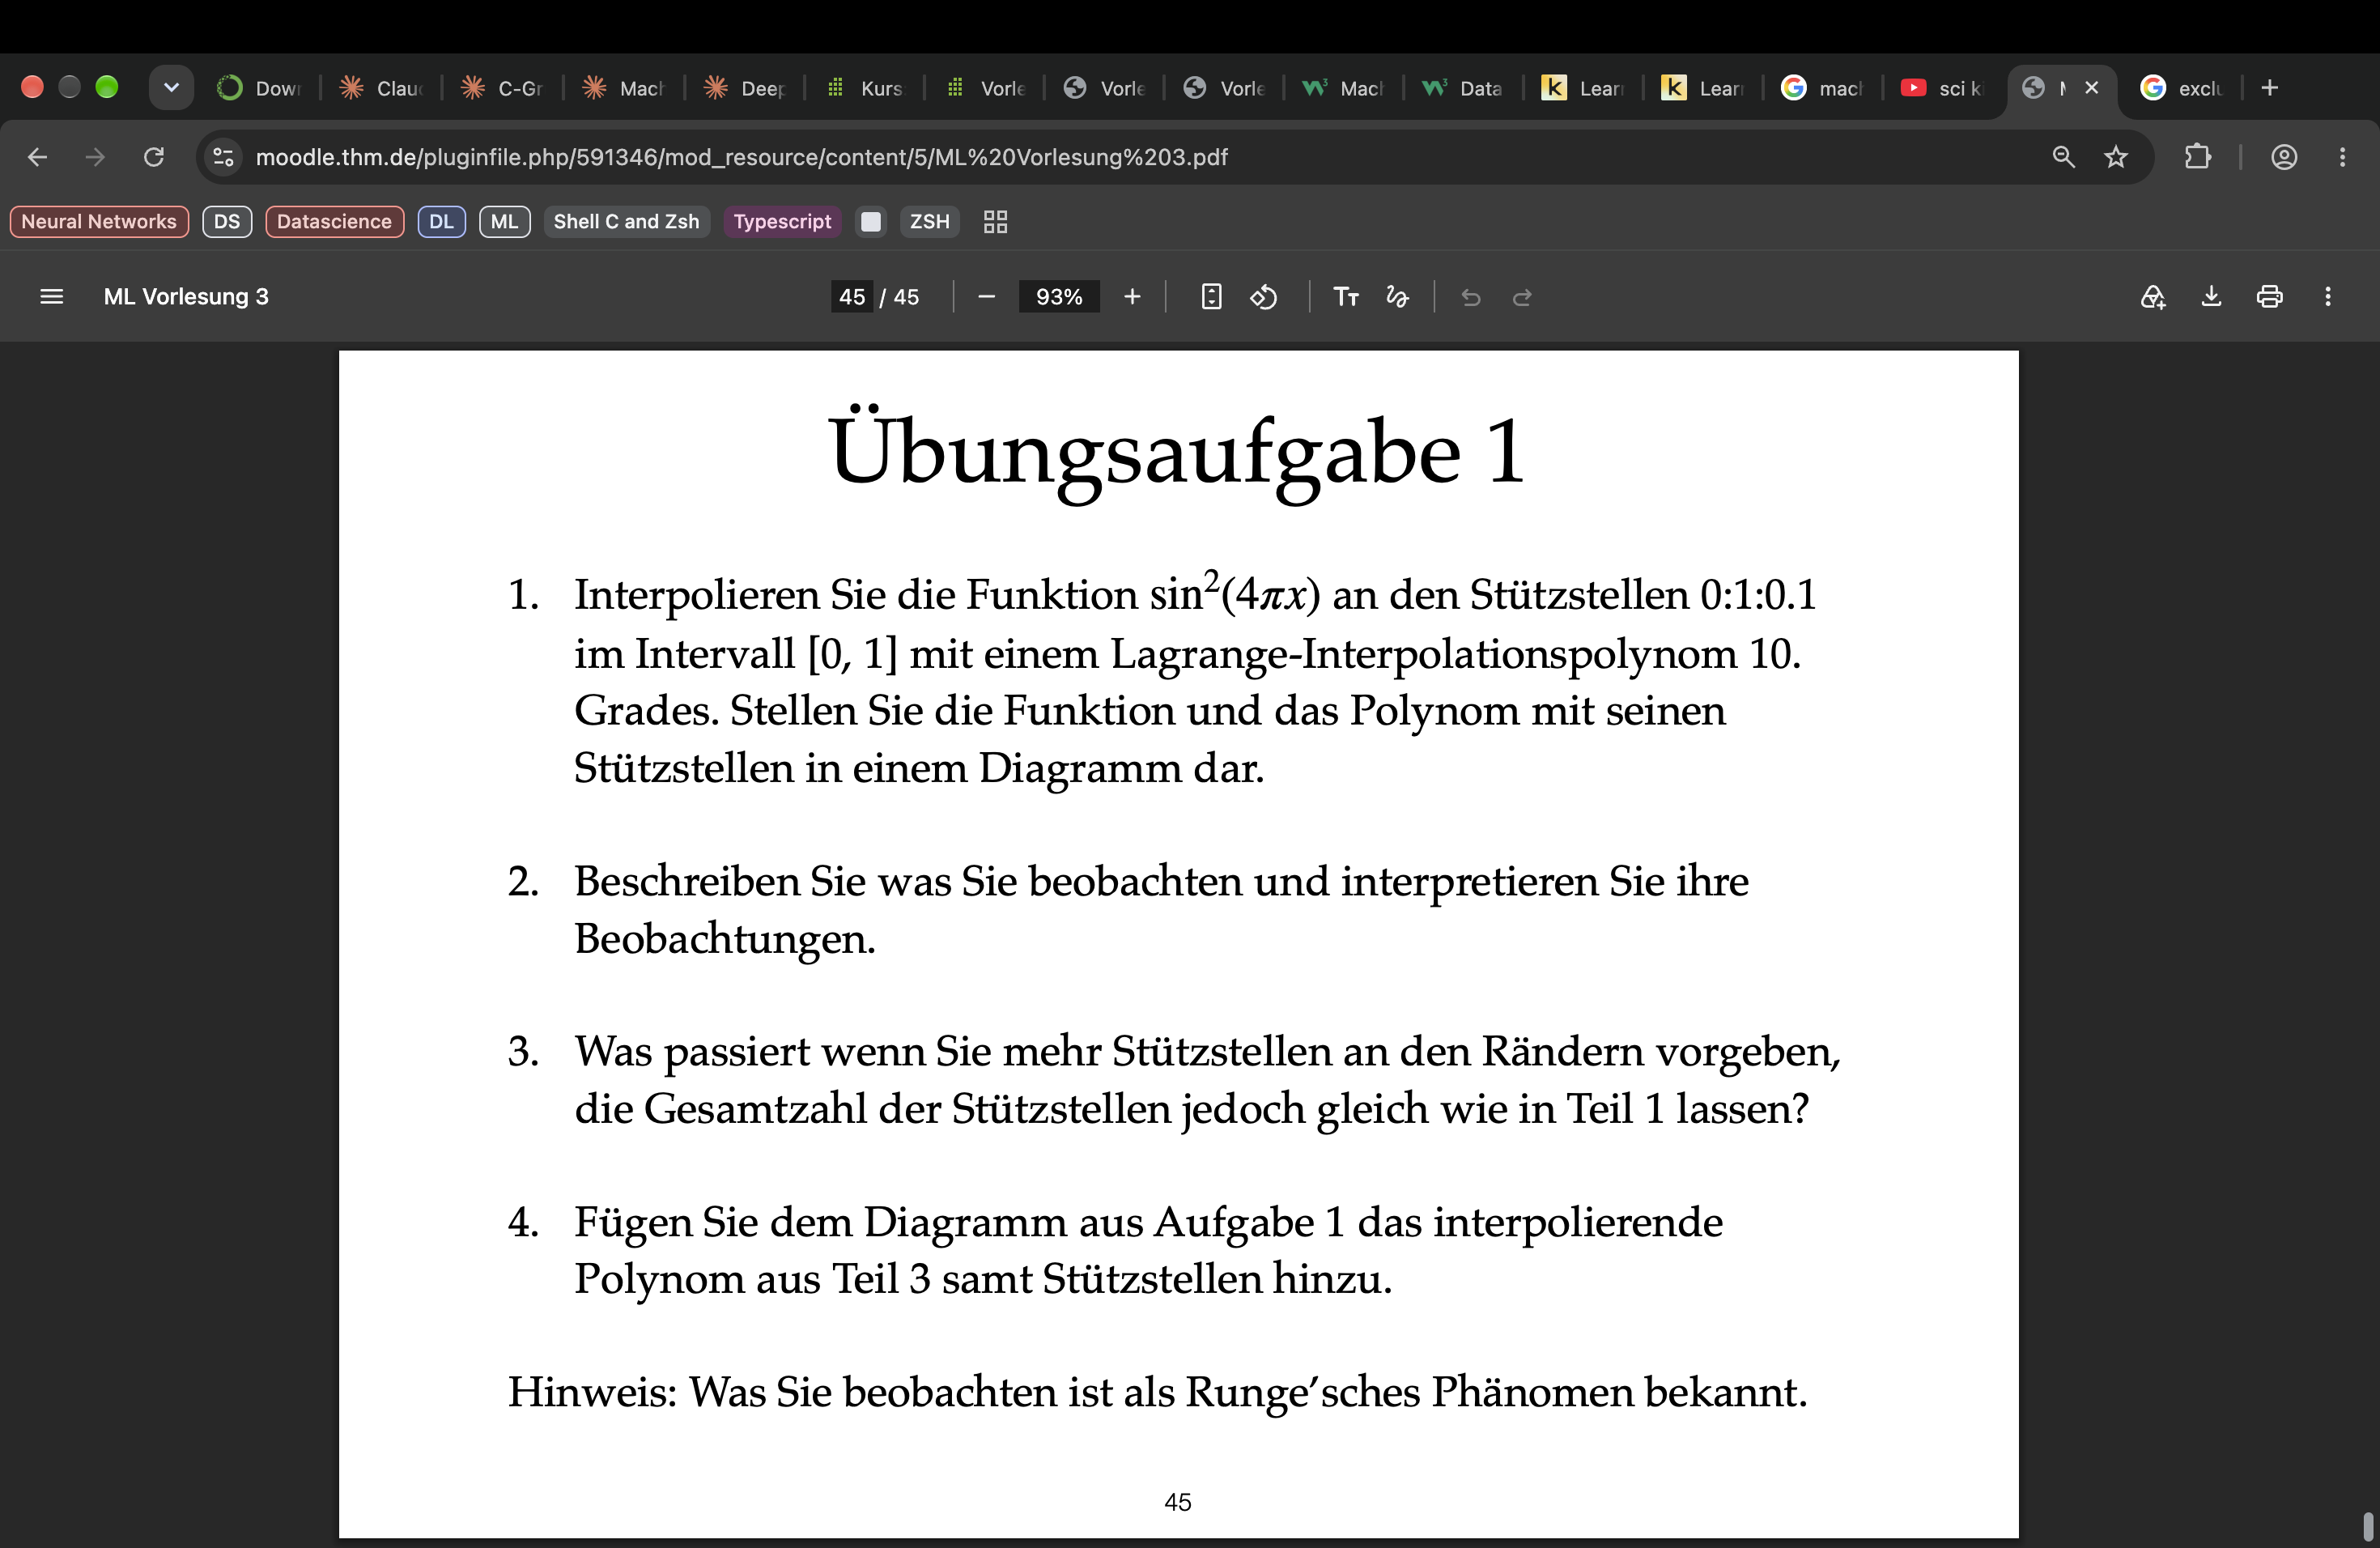

In [71]:
import numpy as np
import matplotlib.pyplot as plt

In [88]:
x_stuetz = np.linspace(0,1,11)
print(x_stuetz)
y_stuetz= np.sin(4*np.pi*x_stuetz)**2
print(y_stuetz)


[0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]
[0.00000000e+00 9.04508497e-01 3.45491503e-01 3.45491503e-01
 9.04508497e-01 5.99903913e-32 9.04508497e-01 3.45491503e-01
 3.45491503e-01 9.04508497e-01 2.39961565e-31]


In [78]:
### Define the function of lagrange
def lagrange(x, x_stuetz,y_stuetz):
    n = len(x_stuetz) ## degree of the polynomial = number of points -1
    result= 0
    for i in range(n):
        L_i = 1
        for j in range(n):
            if j != i:
                L_i=L_i *(x-x_stuetz[j]) / (x_stuetz[i]-x_stuetz[j])
        result = result + y_stuetz[i]*L_i

    return result

##### Test on the function x^2

In [82]:
# x_stuetz= [0,1,2]
# y_stuetz=[0,1,4]
#
# print(lagrange(0,x_stuetz,y_stuetz)) # 0
# print(lagrange(1,x_stuetz,y_stuetz)) # 1
# print(lagrange(2,x_stuetz,y_stuetz))# 4
# print(lagrange(3,x_stuetz,y_stuetz))# 9
# print(lagrange(1.5,x_stuetz,y_stuetz))# 2.25

In [83]:
# evaluation of each value in x_stuetz from the lagrange polynom
for value in x_stuetz:
    print(f"{lagrange(value,x_stuetz,y_stuetz)}")

0.0
0.9045084971874736
0.34549150281252644
0.34549150281252655
0.9045084971874738
5.99903913064743e-32
0.9045084971874741
0.34549150281252655
0.3454915028125259
0.9045084971874741
2.399615652258972e-31


In [84]:
## evalution of the function sin^2(x*pi*4) at each value of x_stuetz
def func(x):
    return np.sin(np.pi*4*x)**2
for value in x_stuetz:
    print(func(value))

0.0
0.9045084971874736
0.34549150281252644
0.34549150281252655
0.9045084971874738
5.99903913064743e-32
0.9045084971874741
0.34549150281252655
0.3454915028125259
0.9045084971874741
2.399615652258972e-31


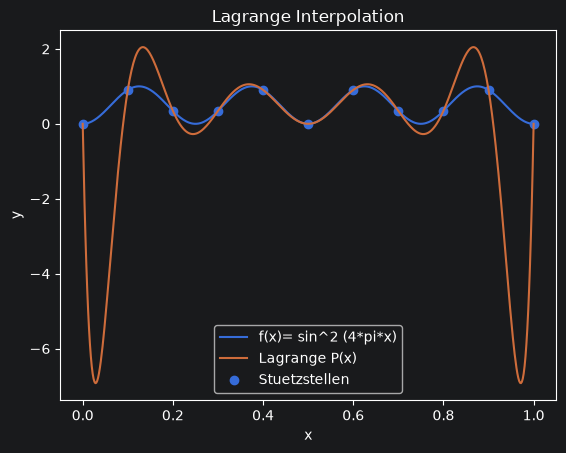

In [89]:
# Plot the functions using matplotlib
x_plot = np.linspace(0,1,500) ##500 points between 0 and 1
f_werte = func(x_plot) # evaluation of the 500 points in the function sin^2 (4*pi*x)
p_werte= np.array([lagrange(x,x_stuetz,y_stuetz) for x in x_plot])#evaluation of the lagrange function  at each point of x_plot
plt.plot(x_plot,f_werte,label="f(x)= sin^2 (4*pi*x)") # plot as a curve from the 500 points in x_plot and y= sin^2(4*pi *x ) for each x in x_plot "line"
plt.plot(x_plot,p_werte,label="Lagrange P(x)") # for each x in x_plot evaluate the lagrange function and plot the curve  "line"
plt.scatter(x_stuetz,y_stuetz,label="Stuetzstellen") # plot the points from the arrays x_stuetz and y_stuetz as points not as a line
plt.xlabel("x") # label the x_axis with x
plt.ylabel("y") # label the y_axis with y
plt.legend() # show the labels of each curve and show the label of the points
plt.title ("Lagrange Interpolation") # give a title to the plot
plt.show() # show the Graph


#### Teilaufgabe 2

Ich sehe, die Punkte an den stützenstellen sowohl von der funktion ***f(x)=sin^2(5\*pi\*x)*** als auch von dem Legrange Polynom getroffen werden, also es gilt P(x) = f(x) for each x in x_stuetze
In der Mitte von dem Plot auf dem Intervall [0.4 ,0.6 ] stimmen die funktionen f(x) und p(x) überein , auf dem Rand oszilliert das Legrange Polynom p(x) -> Runge Phenomenon , auch wenn ich mehr Nodes hinzufüge , der error an den Rand increases statt deceases , d.h. je mehr Punkte, desto schlechter ist die Approximation von dem Interpolation  Polynom an den Rändern und der  Error increases
Der error am rand ist sehr hoch, benutzt mehr nodes für x_stuetz z.B.
``` python
x_stuetz = np.linspace(0,1,15)

```
Um diesen Fehler zu minimieren, statt mehr nodes müssen wir etwas anders benutzen, der Grund an dem Fehler liegt daran dass wir equidistant nodes haben, wir haben 11 nodes der distanz zwischen x_i und x_i+1 ist 0.1. Um das zu verbessern wir werden benutzen die Chebyshev-nodes, das verändert die Position von den Nodes an dem Rand und daher minimieren wir damit erstens den Fehler an dem Rand und zweitens mit mehr Nodes approximieren wir die funktion f(x) besser.

#### Chebyshev-Nodes
Formel

x<sub>i</sub>= $ \frac{a+b} {2} \times  \frac {b-a}{2} \times cos (\frac { 2  (i +1 ) \times \pi } {(2 {n+1})}) $

##### a and b are from the Interval [0,1] where a =0  and b = 1 and n is Number of Intervals

for a = 0 and for b = 1 and n= 10


x<sub>i</sub>= $ \frac {1}{2} - \frac {1} {2} \times cos ( \frac {2(i+1) \pi}{22})$






##### Chebyshev Formel

In [100]:
def chebyshev(a,b,n):
    x_stuetz= []
    for i in range(n+1):
        x_i= ((a+b)/2) - ((b-a) / 2) * np.cos( (2*i + 1)* np.pi / (2*(n+1)))
        x_stuetz.append(x_i)
    return np.array(x_stuetz)


#### Hier haben wir neue nodes nach chebyshev, danach haben wir die y werte neu berechnet von den neuen x-werten, interpolation polynom

In [105]:
x_stuetz_cheby = chebyshev(0,1,10)
y_stuetz_cheby= np.sin(4*np.pi*x_stuetz_cheby)**2

###### PLOT

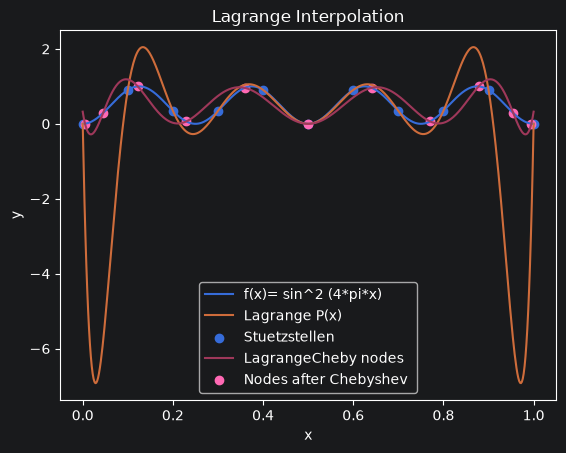

In [109]:
# Plot the functions using matplotlib
x_plot = np.linspace(0,1,500) ##500 points between 0 and 1
f_werte = func(x_plot) # evaluation of the 500 points in the function sin^2 (4*pi*x)
p_werte= np.array([lagrange(x,x_stuetz,y_stuetz) for x in x_plot])#evaluation of the lagrange function  at each point of x_plot
## new
p_werte_cheby= np.array([lagrange(x,x_stuetz_cheby,y_stuetz_cheby) for x in x_plot])#evaluation of the lagrange function  at each point of x_plot
plt.plot(x_plot,f_werte,label="f(x)= sin^2 (4*pi*x)") # plot as a curve from the 500 points in x_plot and y= sin^2(4*pi *x ) for each x in x_plot "line"
plt.plot(x_plot,p_werte,label="Lagrange P(x)") # for each x in x_plot evaluate the lagrange function and plot the curve  "line"
plt.scatter(x_stuetz,y_stuetz,label="Stuetzstellen") # plot the points from the arrays x_stuetz and y_stuetz as points not as a line
### new 2 lines added to the plot above
## neue funktion nach cheby plotten
plt.plot(x_plot,p_werte_cheby,label="LagrangeCheby nodes")
plt.scatter(x_stuetz_cheby,y_stuetz_cheby,label="Nodes after Chebyshev " ,color='hotpink')
##
plt.xlabel("x") # label the x_axis with x
plt.ylabel("y") # label the y_axis with y
plt.legend() # show the labels of each curve and show the label of the points
plt.title ("Lagrange Interpolation") # give a title to the plot
plt.show() # show the Graph